In [1]:
%%configure -f
{
    "jars": ["https://repo1.maven.org/maven2/org/datasyslab/geotools-wrapper/1.9.1-33.5/geotools-wrapper-1.9.1-33.5.jar", "https://repo1.maven.org/maven2/org/apache/sedona/sedona-spark-shaded-4.1_2.13/1.9.1/sedona-spark-shaded-4.1_2.13-1.9.1.jar"]
}

StatementMeta(, 6905cc5b-c186-4abd-b4ce-114737c98de4, -1, Finished, Available, Finished, True)

In [2]:
from pyspark.sql.functions import *
from sedona.spark import SedonaContext
import matplotlib.pyplot as plt

StatementMeta(, 6905cc5b-c186-4abd-b4ce-114737c98de4, 9, Finished, Available, Finished, False)

In [3]:
%run manage_tables

StatementMeta(, 6905cc5b-c186-4abd-b4ce-114737c98de4, 15, Finished, Available, Finished, True)

In [4]:
%run manage_files

StatementMeta(, 6905cc5b-c186-4abd-b4ce-114737c98de4, 21, Finished, Available, Finished, True)

In [5]:
%run transformation

StatementMeta(, 6905cc5b-c186-4abd-b4ce-114737c98de4, 31, Finished, Available, Finished, True)

In [6]:
# silver_df = read_table("yellow_tripdata", "Silver_lakehouse")
# silver_df = silver_df.filter((year(col("pickup_datetime")) == 2009) & (month(col("pickup_datetime")) == 1))\
#     .filter(col("pickup_location_id").isNull() | col("dropoff_location_id").isNull())
# display(silver_df)

StatementMeta(, 18bc1277-1c1b-4166-a42f-4854d31ca319, 28, Finished, Available, Finished, False)

In [6]:
NYC_AREA_MIN_LONGITUDE = -75.5
NYC_AREA_MAX_LONGITUDE = -72.0
NYC_AREA_MIN_LATITUDE = 39.0
NYC_AREA_MAX_LATITUDE = 42.5

StatementMeta(, 6905cc5b-c186-4abd-b4ce-114737c98de4, 32, Finished, Available, Finished, False)

In [7]:
TAXI_ZONES_SHAPEFILE_FOLDER_PATH = "Files/NYC_Taxi/taxi_zones/"

def create_sedona_context(spark):
    return SedonaContext.create(spark)

def read_taxi_zones_shapefile(sedona, file_path):
    return sedona.read.format("org.apache.sedona.sql.datasources.shapefile.ShapefileDataSource").load(file_path)

def create_temp_view(df, view_name):
    df.createOrReplaceTempView(view_name)

def transform_taxi_zones(df):
    return df.selectExpr("*", "ST_Transform(geometry, 'EPSG:2263', 'EPSG:4326') AS new_geometry")

def enrich_taxi_locations(df, sedona):
    create_temp_view(df, "trips")
    return sedona.sql("""
        SELECT trips.pickup_datetime,
            trips.dropoff_datetime,
            trips.passenger_count,
            trips.trip_distance,
            COALESCE(trips.pickup_location_id, MIN(pickup_zone.LocationID)) AS pickup_location_id,
            COALESCE(trips.dropoff_location_id, MIN(dropoff_zone.LocationID)) AS dropoff_location_id,
            trips.fare_amount,
            trips.total_amount,
            trips.tip_amount,
            trips.pickup_longitude,
            trips.pickup_latitude,
            trips.dropoff_longitude,
            trips.dropoff_latitude
        FROM trips
        LEFT JOIN zones AS pickup_zone
        ON trips.pickup_location_id IS NULL
            AND ST_Intersects(pickup_zone.new_geometry, ST_Point(trips.pickup_longitude, trips.pickup_latitude))
        LEFT JOIN zones AS dropoff_zone
        ON trips.dropoff_location_id IS NULL
            AND ST_Intersects(dropoff_zone.new_geometry, ST_Point(trips.dropoff_longitude, trips.dropoff_latitude))
        GROUP BY trips.pickup_datetime, trips.dropoff_datetime, trips.passenger_count, trips.trip_distance, trips.pickup_location_id, trips.dropoff_location_id, trips.fare_amount, trips.total_amount, trips.tip_amount, trips.pickup_longitude, trips.pickup_latitude, trips.dropoff_longitude, trips.dropoff_latitude
    """)

def get_special_location_ids():
    df = read_table("nyc_taxi_zones", "Silver_lakehouse")
    unknown_zone = df.filter(upper(trim(col("Borough"))) == "UNKNOWN").select("LocationID").first()
    outside_nyc_zone = df.filter(upper(trim(col("Borough"))) == "OUTSIDE OF NYC").select("LocationID").first()
    if unknown_zone is None or outside_nyc_zone is None:
        raise ValueError("Could not find Unknown or Outside of NYC zones")
    return unknown_zone["LocationID"], outside_nyc_zone["LocationID"]

def load_taxi_zones(sedona, shapefile_folder_path):
    zones_df = read_taxi_zones_shapefile(sedona, shapefile_folder_path)
    zones_df = transform_taxi_zones(zones_df)
    create_temp_view(zones_df, "zones")

def prepare_spatial_processing(shapefile_folder_path):
    sedona = create_sedona_context(spark)
    load_taxi_zones(sedona, shapefile_folder_path)
    return sedona

StatementMeta(, 6905cc5b-c186-4abd-b4ce-114737c98de4, 33, Finished, Available, Finished, False)

In [8]:
def is_valid_coordinates(longitude_column, latitude_column):
    return (col(longitude_column).between(NYC_AREA_MIN_LONGITUDE, NYC_AREA_MAX_LONGITUDE) & col(latitude_column).between(NYC_AREA_MIN_LATITUDE, NYC_AREA_MAX_LATITUDE))

def filter_taxi_coordinates(df):
    is_pickup_valid = (col("pickup_location_id").isNotNull() | is_valid_coordinates("pickup_longitude", "pickup_latitude"))
    is_dropoff_valid = (col("dropoff_location_id").isNotNull() | is_valid_coordinates("dropoff_longitude", "dropoff_latitude"))
    return df.filter(is_pickup_valid | is_dropoff_valid)

def normalize_taxi(df, column_mapping, schema):
    df = rename_columns(df, column_mapping)
    df = add_missing_columns(df, schema)
    df = cast_columns(df, schema)
    df = select_columns(df, schema)
    return df

def filter_taxi(df):
    df = drop_null_rows(df, ["pickup_datetime", "dropoff_datetime"])
    df = filter_taxi_coordinates(df)
    return df

StatementMeta(, 6905cc5b-c186-4abd-b4ce-114737c98de4, 34, Finished, Available, Finished, False)

In [9]:
def assign_special_location_id(df, location_id, longitude, latitude, unknown_location_id, outside_nyc_location_id):
    return df.withColumn(location_id,
        when(
            col(location_id).isNull() &
            (col(longitude).isNull() | col(latitude).isNull() | (col(longitude) == 0.0) | (col(latitude) == 0.0)),
            unknown_location_id
        ).when(
            col(location_id).isNull() &
            (col(longitude) != 0.0) & (col(latitude) != 0.0),
            outside_nyc_location_id
        ).otherwise(col(location_id))
    )

def assign_special_location_ids(df, unknown_location_id, outside_nyc_location_id):
    for type in ["pickup", "dropoff"]:
        df = assign_special_location_id(df, f"{type}_location_id", f"{type}_longitude", f"{type}_latitude", unknown_location_id, outside_nyc_location_id)
    return df

def filter_nyc_trips(df, unknown_location_id, outside_nyc_location_id):
    return df.filter(
        (~col("pickup_location_id").isin(unknown_location_id, outside_nyc_location_id)) |
        (~col("dropoff_location_id").isin(unknown_location_id, outside_nyc_location_id))
    )

def finalize_taxi_locations(df):
    unknown_location_id, outside_nyc_location_id = get_special_location_ids()
    df = assign_special_location_ids(df, unknown_location_id, outside_nyc_location_id)
    df = filter_nyc_trips(df, unknown_location_id, outside_nyc_location_id)
    return df

StatementMeta(, 6905cc5b-c186-4abd-b4ce-114737c98de4, 35, Finished, Available, Finished, False)

In [10]:
file_path = "Files/NYC_Taxi/yellow_tripdata/yellow_tripdata_2009-01.parquet"
YELLOW_TAXI_SCHEMA = {
    "pickup_datetime": "timestamp",
    "dropoff_datetime": "timestamp",
    "passenger_count": "integer",
    "trip_distance": "double",
    "pickup_location_id": "integer",
    "dropoff_location_id": "integer",
    "pickup_longitude": "double",
    "pickup_latitude": "double",
    "dropoff_longitude": "double",
    "dropoff_latitude": "double",
    "fare_amount": "double",
    "total_amount": "double",
    "tip_amount": "double"
}
YELLOW_TAXI_COLUMN_MAPPING = {
    "Trip_Pickup_DateTime": "pickup_datetime",
    "tpep_pickup_datetime": "pickup_datetime",
    "Trip_Dropoff_DateTime": "dropoff_datetime",
    "tpep_dropoff_datetime": "dropoff_datetime",
    "Passenger_Count": "passenger_count",
    "Trip_Distance": "trip_distance",
    "PULocationID": "pickup_location_id",
    "DOLocationID": "dropoff_location_id",
    "Start_Lon": "pickup_longitude",
    "Start_Lat": "pickup_latitude",
    "End_Lon": "dropoff_longitude",
    "End_Lat": "dropoff_latitude",
    "Fare_Amt": "fare_amount",
    "Total_Amt": "total_amount",
    "Tip_Amt": "tip_amount"
}
# sedona = prepare_spatial_processing(TAXI_ZONES_SHAPEFILE_FOLDER_PATH)
bronze_df = read_parquet_file(file_path)
bronze_df = normalize_taxi(bronze_df, YELLOW_TAXI_COLUMN_MAPPING, YELLOW_TAXI_SCHEMA)
# bronze_df = filter_taxi(bronze_df)
# bronze_df = enrich_taxi_locations(bronze_df, sedona)
# bronze_df = finalize_taxi_locations(bronze_df)
# bronze_df = bronze_df.filter(col("dropoff_location_id")==265)
display(bronze_df)

StatementMeta(, 6905cc5b-c186-4abd-b4ce-114737c98de4, 36, Finished, Available, Finished, False)

SynapseWidget(Synapse.DataFrame, 6317d0e7-3af9-403a-85d5-65210c17d59b)

In [13]:
bronze_df.select(max('total_amount')).show()

StatementMeta(, 6905cc5b-c186-4abd-b4ce-114737c98de4, 42, Finished, Available, Finished, False)

+-----------------+
|max(total_amount)|
+-----------------+
|            234.0|
+-----------------+



StatementMeta(, 6905cc5b-c186-4abd-b4ce-114737c98de4, 40, Finished, Available, Finished, False)

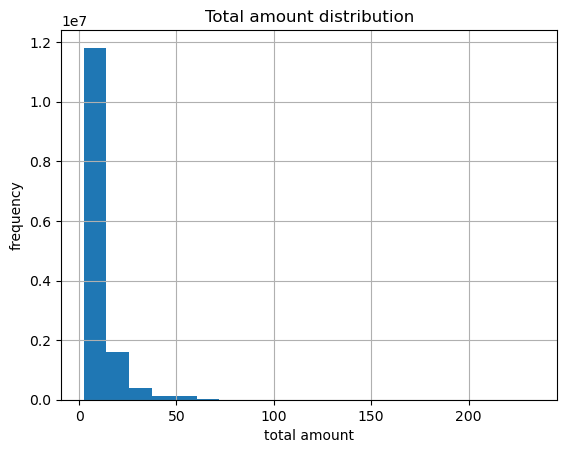

In [12]:
bronze_df.select('total_amount').toPandas().hist(bins=20)
plt.xlabel('total amount')
plt.ylabel('frequency')
plt.title('Total amount distribution')
plt.show()
plt.show()

StatementMeta(, 6905cc5b-c186-4abd-b4ce-114737c98de4, 66, Finished, Available, Finished, False)

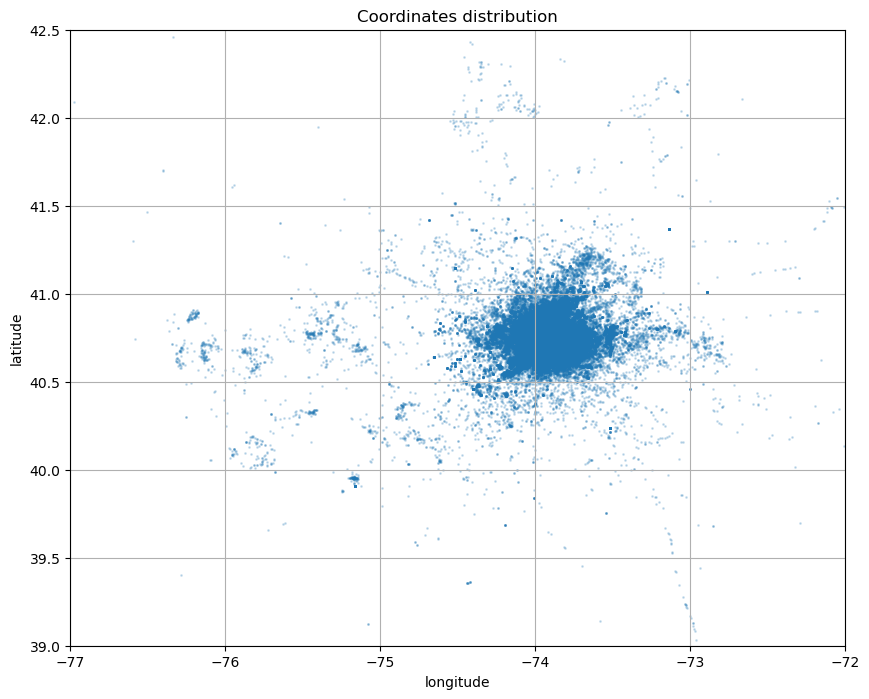

In [17]:
coordinates_df = bronze_df.select(col("pickup_longitude").alias("longitude"), col("pickup_latitude").alias("latitude"))\
    .union(bronze_df.select(col("dropoff_longitude").alias("longitude"), col("dropoff_latitude").alias("latitude")))
# pdf = coordinates_df.sample(False, 0.1, seed=42).limit(100000).toPandas()
pdf = coordinates_df.toPandas()
plt.figure(figsize=(10, 8))
plt.scatter(pdf["longitude"], pdf["latitude"], s=1, alpha=0.2)
plt.xlim(-77, -72)
plt.ylim(39, 42.5)
plt.title("Coordinates distribution")
plt.xlabel("longitude")
plt.ylabel("latitude")
plt.grid()
plt.show()

In [35]:
display(bronze_df.filter((col("dropoff_longitude").between(-80, -76))|(col("pickup_longitude").between(-80, -76))))

StatementMeta(, b3acc8f7-a9bb-4f79-8e55-83e28ee2cace, 214, Finished, Available, Finished, False)

SynapseWidget(Synapse.DataFrame, c4d6de14-0374-4ff9-babb-e058acd86d91)

In [28]:
display(bronze_df.filter(col("dropoff_longitude") < -200))

StatementMeta(, b3acc8f7-a9bb-4f79-8e55-83e28ee2cace, 166, Finished, Available, Finished, False)

SynapseWidget(Synapse.DataFrame, 4c31f5f0-8bb4-4e66-bbc8-8c5c9ab288ac)

In [26]:
display(bronze_df.filter(col("dropoff_latitude") > 250))

StatementMeta(, b3acc8f7-a9bb-4f79-8e55-83e28ee2cace, 164, Finished, Available, Finished, False)

SynapseWidget(Synapse.DataFrame, 05c15b93-2a57-40e6-951e-be2f51a332ff)

In [19]:
display(bronze_df.filter(col("pickup_longitude") > 1000))

StatementMeta(, b3acc8f7-a9bb-4f79-8e55-83e28ee2cace, 104, Finished, Available, Finished, False)

SynapseWidget(Synapse.DataFrame, b5b5ce0b-9588-44d5-a514-3bd5f87909e9)

In [51]:
new_df = read_parquet_file("Files/NYC_Taxi/yellow_tripdata/yellow_tripdata_2020-04.parquet")
new_df = normalize_taxi(new_df, YELLOW_TAXI_COLUMN_MAPPING, YELLOW_TAXI_SCHEMA)
new_df = filter_taxi(new_df)
new_df = enrich_taxi_locations(new_df, sedona)
new_df = finalize_taxi_locations(new_df)
display(new_df)

StatementMeta(, 3f3219a4-4603-4aa2-9598-7d834f4a4fc4, 82, Finished, Available, Finished, False)

SynapseWidget(Synapse.DataFrame, dc969a41-f441-402d-98b0-00806e78acaf)

In [20]:
sedona.sql("""
    SELECT ST_AsText(ST_Boundary(new_geometry))
    FROM zones
    WHERE LocationID = 164
""").show(truncate=False)

StatementMeta(, 9fb5784e-8127-4f49-9273-3ae766d6b02c, 41, Finished, Available, Finished, False)

+---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

In [21]:
sedona.sql("""
    SELECT LocationID
    FROM zones
    WHERE ST_Intersects(new_geometry, ST_Point(-73.98362519999995, 40.74394311499994))
""").show()

StatementMeta(, 9fb5784e-8127-4f49-9273-3ae766d6b02c, 42, Finished, Available, Finished, False)

+----------+
|LocationID|
+----------+
|       164|
|       170|
+----------+



In [36]:
sedona.sql("""
    SELECT LocationID
    FROM zones
    WHERE ST_Contains(new_geometry, ST_Point(-76.09280699999998, 40.678185))
""").show()

StatementMeta(, b3acc8f7-a9bb-4f79-8e55-83e28ee2cace, 215, Finished, Available, Finished, False)

NameError: name 'sedona' is not defined

In [3]:
YELLOW_TAXI_FOLDER_PATH = "Files/NYC_Taxi/yellow_tripdata"
file_paths = get_parquet_files(YELLOW_TAXI_FOLDER_PATH)
schemas = {}
for file_path in file_paths:
    df = read_parquet_file(file_path)
    schema = df.schema.json()
    if schema not in schemas:
        schemas[schema] = []
    schemas[schema].append(file_path)
print(f"Total files: {len(file_paths)}")
print(f"Unique schemas: {len(schemas)}")
for i, (schema, paths) in enumerate(schemas.items(), start=1):
    print(f"\n--- Schema {i} ({len(paths)} files) ---")
    print(paths[0])
    print(spark.read.parquet(paths[0])._jdf.schema().treeString())

StatementMeta(, dd62087d-66b1-4d80-aebd-da5e93ad5585, 10, Finished, Available, Finished, False)

Total files: 213
Unique schemas: 13

--- Schema 1 (12 files) ---
abfss://7267c3dd-58a1-43e7-8700-fdb441903273@onelake.dfs.fabric.microsoft.com/fa985e23-5a98-434b-8ff5-2c39b7a229d4/Files/NYC_Taxi/yellow_tripdata/yellow_tripdata_2009-01.parquet
root
 |-- vendor_name: string (nullable = true)
 |-- Trip_Pickup_DateTime: string (nullable = true)
 |-- Trip_Dropoff_DateTime: string (nullable = true)
 |-- Passenger_Count: long (nullable = true)
 |-- Trip_Distance: double (nullable = true)
 |-- Start_Lon: double (nullable = true)
 |-- Start_Lat: double (nullable = true)
 |-- Rate_Code: double (nullable = true)
 |-- store_and_forward: double (nullable = true)
 |-- End_Lon: double (nullable = true)
 |-- End_Lat: double (nullable = true)
 |-- Payment_Type: string (nullable = true)
 |-- Fare_Amt: double (nullable = true)
 |-- surcharge: double (nullable = true)
 |-- mta_tax: double (nullable = true)
 |-- Tip_Amt: double (nullable = true)
 |-- Tolls_Amt: double (nullable = true)
 |-- Total_Amt: doub